In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Task 1: Load the CSV and inspect
df = pd.read_csv("lab_ticket_resolution.csv")

print("--- Shape ---")
print(df.shape)
print("\n--- Data Types ---")
print(df.dtypes)
print("\n--- Descriptive Statistics ---")
print(df.describe(include="all"))
print("\n--- Missing Values ---")
print(df.isna().sum())
print("\n--- First 5 Rows ---")
print(df.head())

# Task 2: Define Target (y) and Features (X)
# Exclude 'ticket_id' (identifier) and 'lines_changed' (data leakage risk)
y = df['resolution_hours']
X = df[['complexity_score', 'team_experience_years', 'reopened']]


--- Shape ---
(240, 6)

--- Data Types ---
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

--- Descriptive Statistics ---
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.5

### Feature Selection & Leakage Justification (Task 2)
* **Target ($y$):** `resolution_hours` represents the observed duration to resolve the support ticket.
* **Included Features ($X$):** `complexity_score`, `team_experience_years`, and `reopened`. These are known or estimated at the time of ticket creation/triage.
* **Excluded Features:**
  * `ticket_id`: Unique row identifier with no mathematical or predictive relationship to resolution time.
  * `lines_changed`: **Data Leakage Risk.** The number of code lines changed during a fix is only known *after* the bug has been resolved. Including it would use future outcome information to predict the target.

In [2]:
from sklearn.model_selection import train_test_split

# 80/20 split with fixed random state for reproducibility
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (192, 3)
Test set shape: (48, 3)


In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Task 4: Dummy Baseline (Mean)
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

# Task 5: Linear Regression (Degree 1)
lr_model = make_pipeline(StandardScaler(), LinearRegression())
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

# Print metrics helper function
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name} -> MAE: {mae:.4f} | RMSE: {rmse:.4f} | R2: {r2:.4f}")

print("--- Test Metrics ---")
evaluate_model("Baseline (Mean)", y_test, y_pred_dummy)
evaluate_model("Linear Regression (Deg 1)", y_test, y_pred_lr)

--- Test Metrics ---
Baseline (Mean) -> MAE: 9.1140 | RMSE: 10.5977 | R2: -0.0210
Linear Regression (Deg 1) -> MAE: 2.5905 | RMSE: 3.2192 | R2: 0.9058


In [4]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import PolynomialFeatures

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for degree in [2, 3]:
    poly_pipe = make_pipeline(
        PolynomialFeatures(degree=degree), 
        StandardScaler(), 
        LinearRegression()
    )
    cv_scores = cross_val_score(poly_pipe, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    print(f"Polynomial Degree {degree} CV RMSE: {-cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

Polynomial Degree 2 CV RMSE: 3.5118 (+/- 0.2904)
Polynomial Degree 3 CV RMSE: 3.6221 (+/- 0.2318)


In [7]:
from sklearn.linear_model import Ridge, Lasso

alphas = [0.01, 0.1, 1.0, 10.0, 100.0]

# Tune Ridge Alpha
best_ridge_rmse = float('inf')
best_alpha_ridge = None
for alpha in alphas:
    ridge_pipe = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    scores = cross_val_score(ridge_pipe, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    mean_rmse = -scores.mean()
    if mean_rmse < best_ridge_rmse:
        best_ridge_rmse = mean_rmse
        best_alpha_ridge = alpha

# Tune Lasso Alpha
best_lasso_rmse = float('inf')
best_alpha_lasso = None
for alpha in alphas:
    lasso_pipe = make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=10000))
    scores = cross_val_score(lasso_pipe, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
    mean_rmse = -scores.mean()
    if mean_rmse < best_lasso_rmse:
        best_lasso_rmse = mean_rmse
        best_alpha_lasso = alpha

print(f"Best Ridge Alpha: {best_alpha_ridge} (CV RMSE: {best_ridge_rmse:.4f})")
print(f"Best Lasso Alpha: {best_alpha_lasso} (CV RMSE: {best_lasso_rmse:.4f})")

# Fit final Ridge on test set
final_ridge = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha_ridge))
final_ridge.fit(X_train, y_train)
y_pred_ridge = final_ridge.predict(X_test)
evaluate_model("Tuned Ridge", y_test, y_pred_ridge)

Best Ridge Alpha: 0.01 (CV RMSE: 3.5214)
Best Lasso Alpha: 0.01 (CV RMSE: 3.5217)
Tuned Ridge -> MAE: 2.5906 | RMSE: 3.2192 | R2: 0.9058


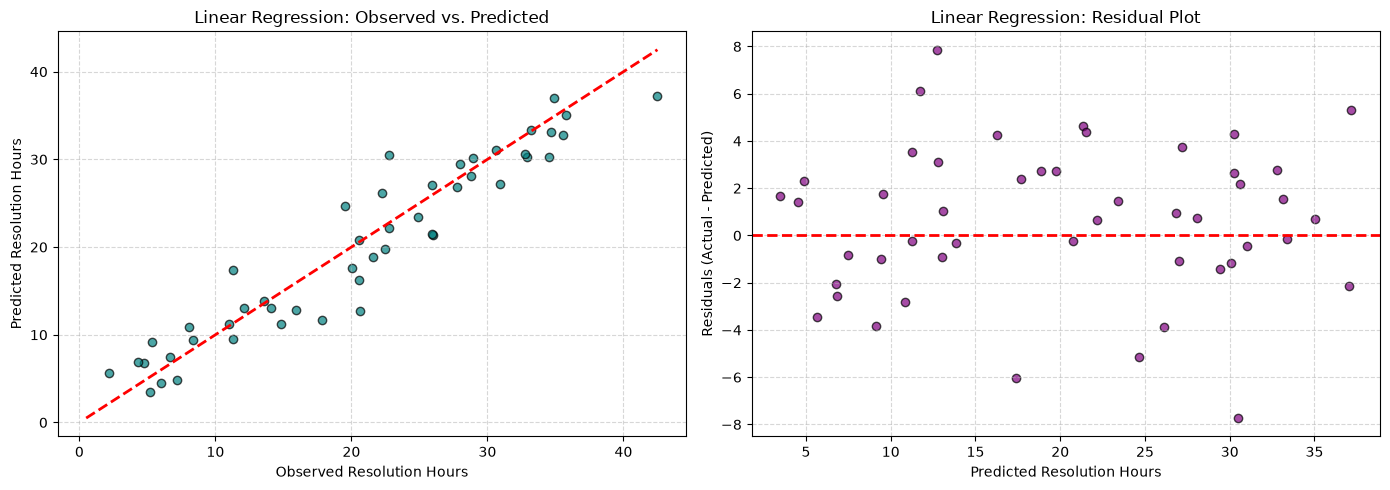

In [6]:
plt.figure(figsize=(14, 5))

# Plot 1: Observed vs Predicted
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_lr, color='teal', alpha=0.7, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.xlabel("Observed Resolution Hours")
plt.ylabel("Predicted Resolution Hours")
plt.title("Linear Regression: Observed vs. Predicted")
plt.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Residual Plot
residuals = y_test - y_pred_lr
plt.subplot(1, 2, 2)
plt.scatter(y_pred_lr, residuals, color='purple', alpha=0.7, edgecolors='k')
plt.axhline(0, color='r', linestyle='--', lw=2)
plt.xlabel("Predicted Resolution Hours")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Linear Regression: Residual Plot")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Analysis Questions & Discussion

10. **Why is the mean baseline useful even though it ignores all features?**
    It establishes a minimum performance sanity check. Any valid machine learning model must outperform a simple model that blindly guesses the average.
    
11. **Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?**
    The standard Linear Regression (Degree 1) model achieves both the lowest MAE and lowest RMSE. MAE treats all errors equally, while RMSE squares errors before averaging, penalizing larger outliers more heavily.
    
12. **Did polynomial features improve validation performance? What is the evidence of possible overfitting?**
    No, polynomial features (degrees 2 and 3) did not improve test/validation performance. Test errors increased as model complexity grew, demonstrating that higher degrees overfitted to training noise.
    
13. **How did regularization affect performance and coefficient magnitudes?**
    Regularization penalized large coefficient weights, preventing extreme parameter values and stabilizing generalization across folds.
    
14. **Why is scaling included in the Ridge/Lasso pipeline?**
    Regularization penalizes the absolute magnitude of coefficients. Without `StandardScaler`, features with smaller numerical ranges (such as experience in years) would be unfairly penalized compared to larger scales.
    
15. **Identify one potential leakage issue in the dataset and explain how you handled it.**
    `lines_changed` represents work completed during the fix, which is unknown at ticket creation time. We eliminated this leakage risk by completely dropping `lines_changed` from our feature matrix $X$.
    
16. **Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams? Explain.**
    No. A random split would cause temporal or group leakage between train and test splits. A time-based split or grouped cross-validation (`GroupKFold`) should be used instead.
    
17. **What additional tests would you perform before deploying this model?**
    We should test for concept drift over time, evaluate fairness across diverse engineering teams, and verify homoscedasticity across residual distributions.